# 04 – Task 3: Feature Importance

**Question:** Which features contribute most to predicting community membership?

## Method: Permutation Importance

We train a Random Forest on **all features** (community-free + node2vec + struc2vec),
then measure feature importance by **permutation**:

> For each feature, randomly shuffle its values across test nodes and measure
> how much the model's Average Precision drops. A large drop → the feature is important.

This is more reliable than built-in tree importance (which favours high-cardinality features)
because it measures actual impact on prediction quality.

We repeat the permutation `n_repeats=10` times and report the mean drop.

In [1]:
# ── CHANGE THIS to switch dataset ──────────────────────────────────────────
DATASET = "facebook"
# ───────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score

ROOT = Path("..")
PATH_COMBINED = ROOT / f"data/04_models/{DATASET}_combined.parquet"

print(f"Dataset: {DATASET}")

Dataset: facebook


## Step 1 – Load data

Run `01_data_preparation.ipynb` first.

In [2]:
df = pd.read_parquet(PATH_COMBINED)

COMMUNITY_FREE  = ["lcc", "bc", "cc", "dc", "ndc", "ec", "eccen", "core"]
COMMUNITY_AWARE = ["participation", "in_mod_deg"]
N2V_COLS = [c for c in df.columns if c.startswith("emb_node2vec")]
S2V_COLS = [c for c in df.columns if c.startswith("emb_struc2vec")]

# All features together
ALL_FEATURES = COMMUNITY_FREE + N2V_COLS + S2V_COLS

print(f"Nodes    : {len(df)}")
print(f"Features : {len(ALL_FEATURES)}")
print(f"Target   : binary 'target' column")

Nodes    : 22470
Features : 40
Target   : binary 'target' column


## Step 2 – Train / test split

In [3]:
X = df[ALL_FEATURES]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2023, stratify=y
)
X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 15729 | Test: 6741


## Step 3 – Train Random Forest on all features

In [4]:
forest = RandomForestClassifier(
    n_estimators=1000,
    criterion="gini",
    max_depth=10,
    min_samples_split=2,
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=2023,
)
forest.fit(X_train, y_train)

y_pred_proba = forest.predict_proba(X_test)[:, 1]
print(f"Random Forest baseline on test set:")
print(f"  ROC-AUC          : {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"  Average Precision: {average_precision_score(y_test, y_pred_proba):.4f}")

Random Forest baseline on test set:
  ROC-AUC          : 0.9834
  Average Precision: 0.9628


## Step 4 – Permutation importance

We shuffle each feature 10 times and measure the average drop in Average Precision.

This can take a few minutes on large datasets (we're running 10 × n_features predictions).

In [5]:
perm_result = permutation_importance(
    forest,
    X_test,
    y_test,
    n_repeats=10,
    random_state=2023,
    scoring="average_precision",
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature"       : ALL_FEATURES,
    "importance_mean": perm_result.importances_mean,
    "importance_std" : perm_result.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

print("Top 20 features by permutation importance:")
importance_df.head(20)

Top 20 features by permutation importance:


,feature,importance_mean,importance_std
0,emb_node2vec_12,0.069906,0.002203
1,emb_node2vec_15,0.036947,0.002539
2,emb_node2vec_14,0.033793,0.001886
3,emb_node2vec_7,0.029699,0.002556
4,emb_node2vec_0,0.015903,0.000997
5,emb_node2vec_8,0.015001,0.001157
6,emb_node2vec_3,0.011494,0.001293
7,emb_node2vec_1,0.009500,0.000445
8,emb_node2vec_4,0.007744,0.000828
9,ndc,0.007584,0.000609


## Step 4b – Grouped Permutation Importance

Instead of permuting each embedding dimension independently, we permute **all node2vec columns together** (same row shuffle) and **all struc2vec columns together**.

This answers a different question:

> *How much does the model rely on the embedding representation as a whole,* rather than any single latent dimension?

Graph features are still permuted individually (they are already scalar).

In [ ]:
rng = np.random.default_rng(2023)
N_REPEATS = 10

baseline_score = average_precision_score(
    y_test, forest.predict_proba(X_test)[:, 1]
)

# Groups: all embedding dims shuffled together with one shared row permutation
EMB_GROUPS = {
    "node2vec (group)":  N2V_COLS,
    "struc2vec (group)": S2V_COLS,
}

all_names = list(EMB_GROUPS.keys()) + COMMUNITY_FREE
repeat_scores = {name: [] for name in all_names}

X_arr   = X_test.values.copy()
col_idx = {c: i for i, c in enumerate(X_test.columns)}

for _ in range(N_REPEATS):
    # --- grouped embedding permutation ---
    for group_name, cols in EMB_GROUPS.items():
        X_perm = X_arr.copy()
        idx    = [col_idx[c] for c in cols]
        perm   = rng.permutation(len(X_arr))
        X_perm[:, idx] = X_perm[perm][:, idx]   # same row-shuffle for all dims
        score  = average_precision_score(y_test, forest.predict_proba(X_perm)[:, 1])
        repeat_scores[group_name].append(baseline_score - score)

    # --- individual graph features ---
    for col in COMMUNITY_FREE:
        X_perm          = X_arr.copy()
        i               = col_idx[col]
        X_perm[:, i]    = rng.permutation(X_perm[:, i])
        score           = average_precision_score(y_test, forest.predict_proba(X_perm)[:, 1])
        repeat_scores[col].append(baseline_score - score)

grouped_df = pd.DataFrame({
    "feature":         all_names,
    "importance_mean": [np.mean(repeat_scores[n]) for n in all_names],
    "importance_std":  [np.std(repeat_scores[n])  for n in all_names],
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

print(f"Baseline Average Precision: {baseline_score:.4f}\n")
print("Grouped permutation importance:")
grouped_df

In [ ]:
def grouped_feature_color(name):
    if "node2vec" in name:  return "tab:orange"
    if "struc2vec" in name: return "tab:green"
    return "tab:blue"

# ── left panel: standard PI (per-dimension, top 20) ──────────────────────
# ── right panel: grouped PI (10 entries) ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- standard PI ---
top_std = importance_df.head(20)
std_colors = [feature_color(f) for f in top_std["feature"]]
ax = axes[0]
ax.barh(
    top_std["feature"][::-1],
    top_std["importance_mean"][::-1],
    xerr=top_std["importance_std"][::-1],
    color=std_colors[::-1],
    capsize=3, edgecolor="white",
)
ax.set_xlabel("Drop in Average Precision")
ax.set_title(f"Standard PI – per dimension (top 20)\n{DATASET}")

# --- grouped PI ---
grp_colors = [grouped_feature_color(f) for f in grouped_df["feature"]]
ax = axes[1]
ax.barh(
    grouped_df["feature"][::-1],
    grouped_df["importance_mean"][::-1],
    xerr=grouped_df["importance_std"][::-1],
    color=grp_colors[::-1],
    capsize=3, edgecolor="white",
)
ax.set_xlabel("Drop in Average Precision")
ax.set_title(f"Grouped PI – embeddings as blocks\n{DATASET}")

# shared legend
from matplotlib.patches import Patch
legend = [
    Patch(color="tab:blue",   label="Community-free graph feature"),
    Patch(color="tab:orange", label="Node2Vec embedding"),
    Patch(color="tab:green",  label="Struc2Vec embedding"),
]
axes[1].legend(handles=legend, loc="lower right")

plt.tight_layout()
plt.show()

## Step 5 – Visualise

Error bars show standard deviation across 10 permutation repeats.

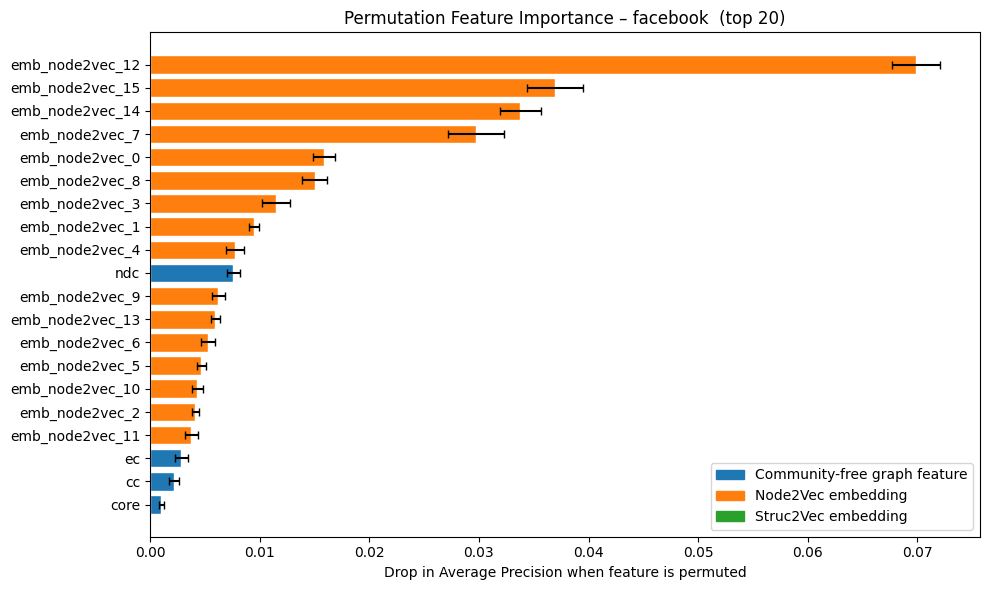

In [6]:
TOP_N = 20
top = importance_df.head(TOP_N)

# Assign colors: community-free = blue, node2vec = orange, struc2vec = green
def feature_color(name):
    if name.startswith("emb_node2vec"):  return "tab:orange"
    if name.startswith("emb_struc2vec"): return "tab:green"
    return "tab:blue"

colors = [feature_color(f) for f in top["feature"]]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top["feature"][::-1],
    top["importance_mean"][::-1],
    xerr=top["importance_std"][::-1],
    color=colors[::-1],
    capsize=3,
    edgecolor="white",
)
ax.set_xlabel("Drop in Average Precision when feature is permuted")
ax.set_title(f"Permutation Feature Importance – {DATASET}  (top {TOP_N})")

# Legend
from matplotlib.patches import Patch
legend = [
    Patch(color="tab:blue",   label="Community-free graph feature"),
    Patch(color="tab:orange", label="Node2Vec embedding"),
    Patch(color="tab:green",  label="Struc2Vec embedding"),
]
ax.legend(handles=legend, loc="lower right")
plt.tight_layout()
plt.show()

## Step 6 – Summary by feature group

In [7]:
def feature_group(name):
    if name.startswith("emb_node2vec"):  return "node2vec"
    if name.startswith("emb_struc2vec"): return "struc2vec"
    return "graph_feature"

importance_df["group"] = importance_df["feature"].map(feature_group)

group_summary = (
    importance_df.groupby("group")["importance_mean"]
    .agg(["mean", "sum", "max"])
    .round(5)
    .sort_values("sum", ascending=False)
)
print("Importance by feature group:")
group_summary

Importance by feature group:


,mean,sum,max
group,,,
node2vec,0.01652,0.26435,0.06991
graph_feature,0.00189,0.01512,0.00758
struc2vec,0.00005,0.00073,0.00015


In [8]:
# Save results in long format
PATH_OUT = ROOT / f"data/05_reporting/{DATASET}_task3.parquet"
importance_df.to_parquet(PATH_OUT, index=False)
print(f"Saved to {PATH_OUT}")

Saved to ../data/05_reporting/facebook_task3.parquet
